### Name : Sheik Faizal S
### reg no: 212224240151
### dept : AIML

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

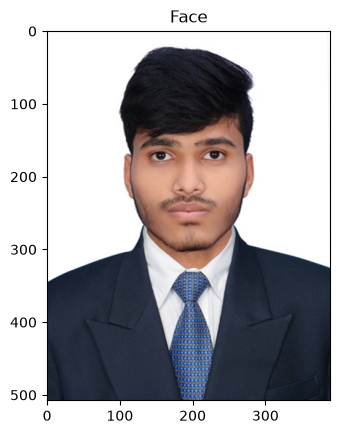

In [42]:
# Load the Face Image
faceImage = cv2.imread('my_pic.jpg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [43]:
faceImage.shape

(508, 390, 3)

In [44]:
#resized_faceImage.shape
faceImage.shape

(508, 390, 3)

Text(0.5, 1.0, 'glassPNG')

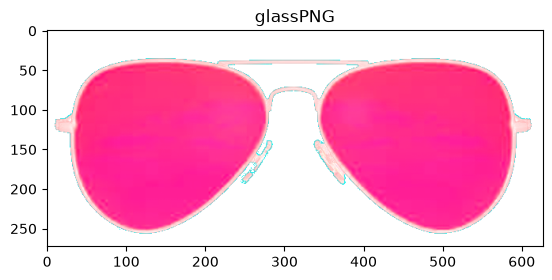

In [45]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('kannadi.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [53]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG, (150, 45))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(45, 150, 4)


In [54]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

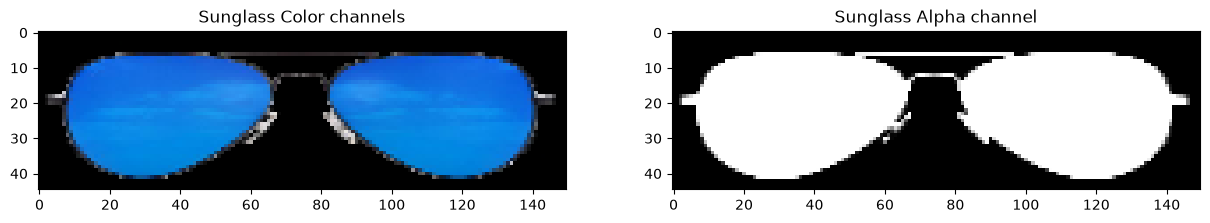

In [55]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

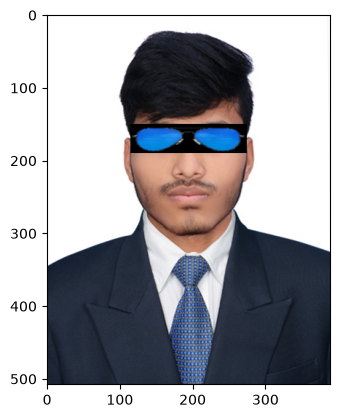

In [62]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Reduce sunglasses size (width=160, height=40)
glassBGR = cv2.resize(glassBGR, (160, 40))

# Place sunglasses over the eyes
faceWithGlassesNaive[150:190, 115:275] = glassBGR

# Display the result
plt.imshow(faceWithGlassesNaive[..., ::-1])
plt.show()

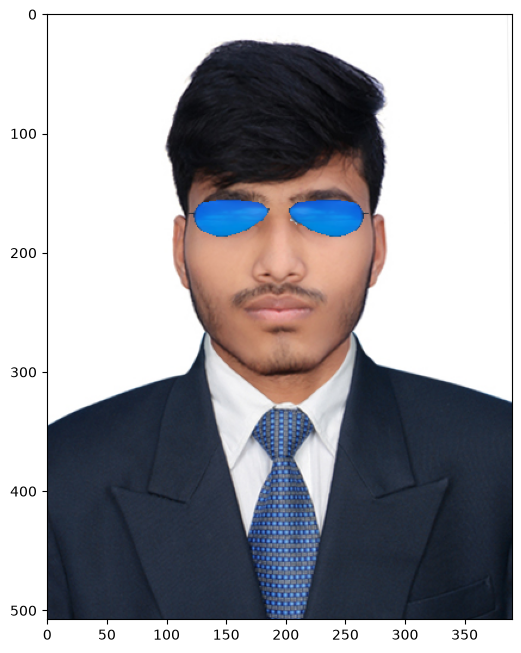

In [64]:

# Sunglasses dimensions
glassBGR = cv2.resize(glassBGR, (160, 40))
glassMask1 = cv2.resize(glassMask1, (160, 40))

# Mask
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))
glassMask = np.uint8(glassMask / 255)

# Copy original image
faceWithGlassesArithmetic = faceImage.copy()

# Correct eye region
y1, y2 = 150, 190
x1, x2 = 115, 275

eyeROI = faceWithGlassesArithmetic[y1:y2, x1:x2]

# Apply mask
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)
maskedGlass = cv2.multiply(glassBGR, glassMask)
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Insert sunglasses
faceWithGlassesArithmetic[y1:y2, x1:x2] = eyeRoiFinal

# Display
plt.figure(figsize=(6, 8))
plt.imshow(faceWithGlassesArithmetic[..., ::-1])
plt.show()


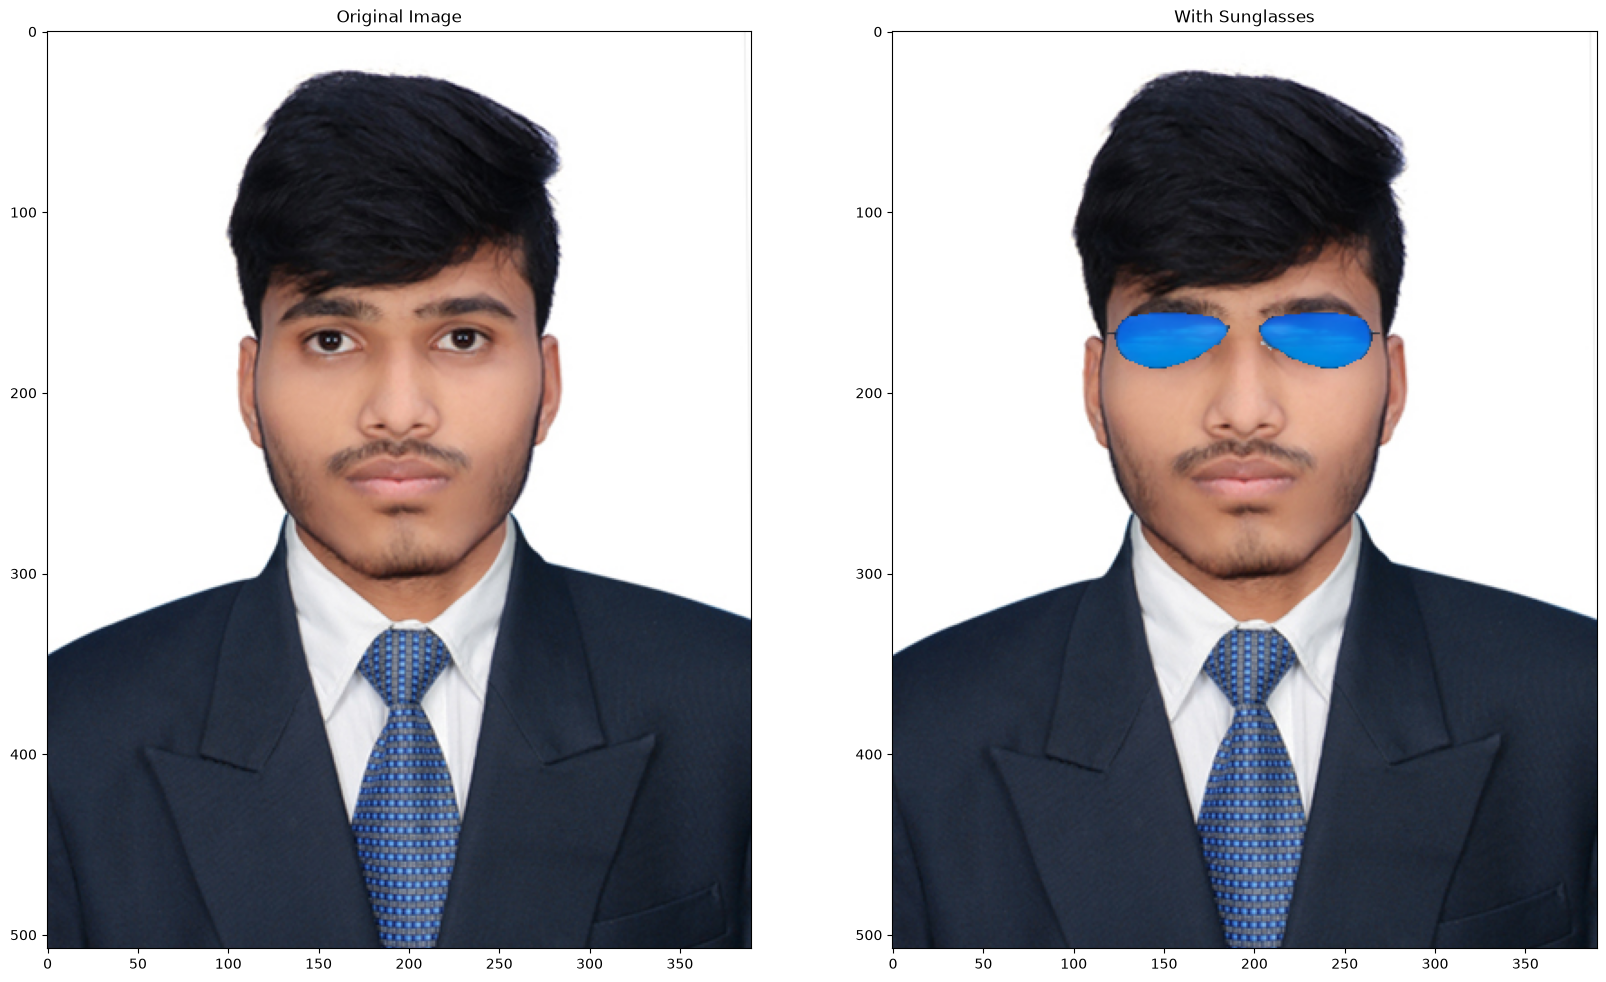

In [65]:

# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[150:190, 115:275] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20, 20])
plt.subplot(121)
plt.imshow(faceImage[:, :, ::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")

plt.show()
